[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/09-system-design/01_estimation.ipynb)

*System Design · Notebook 1 of 10*

# Requirements & Back-of-the-Envelope Estimation

Every design starts with numbers: requests per second and peaks, storage with replication, bandwidth, read/write ratios, latency numbers, availability nines, servers, shards and cache size, Little's law, tail latency under fan-out, IDs and cost.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Estimation is packing for a trip: you don't need the exact weight of every shirt, just enough to know whether it fits in one bag or needs a truck.

**What interviewers really test here:** Clarifying requirements, QPS and peak, storage and bandwidth, latency numbers, nines of availability, and what each number means for the design.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. How a system design interview works *(Basics)*
- [ ] 2. Estimation: the numbers to know *(Basics)*
- [ ] 3. From numbers to machines *(Core)*
- [ ] 4. Latency and availability *(Core)*
- [ ] 5. IDs, units, cost and growth *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import json
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Non-functional requirements to ask about

| Property | Question to ask |
| --- | --- |
| Scale | How many users, requests per second, items stored? |
| Latency | How fast must reads and writes be (p50, p99)? |
| Availability | How many nines? What happens during an outage? |
| Consistency | Must every reader see the latest write immediately? |
| Durability | Can we ever lose data? |
| Cost, security, compliance | Budgets, data residency, privacy rules |

### Powers of ten

| Power | Name | Bytes |
| --- | --- | --- |
| 10³ | thousand | KB |
| 10⁶ | million | MB |
| 10⁹ | billion | GB |
| 10¹² | trillion | TB |
| 10¹⁵ | quadrillion | PB |

---
# Part 2: Lessons, step by step

## Lesson 1: How a system design interview works

*Level: Basics*

A system design round is a 35–60 minute conversation about building a large system ("design a URL shortener", "design WhatsApp"). There's no single right answer. Interviewers judge **how you think**: do you clarify, size the problem, choose sensible components, and explain trade-offs?



A framework that works for every question:




1. **Requirements (5 min)**: what must it do (functional) and how well (non-functional: latency, availability, consistency, scale). Ask; don't assume.
2. **Estimation (5 min)**: users, QPS and peak, storage, bandwidth. The numbers decide the design.
3. **High-level design (10–15 min)**: API, data model, the main boxes and arrows.
4. **Deep dives (15–20 min)**: the hard parts — scaling the hot path, failures, consistency, bottlenecks.
5. **Wrap up**: trade-offs you made, what you'd monitor, what breaks first at 10× scale.

**✏️ Your turn:** you now have what you need for [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 2: Estimation: the numbers to know

*Level: Basics*

| Fact | Value to remember |
| --- | --- |
| Seconds in a day | 86,400 ≈ 10⁵ |
| 1 million requests a day | ≈ 12 per second |
| Peak vs average | 2–5× (measure if you can) |
| Memory read | ~100 ns |
| SSD random read | ~100 µs |
| Round trip in one data centre | ~0.5 ms |
| Round trip across continents | ~150 ms |
| A typical app server | a few thousand simple requests/s |



Work in powers of ten, say every assumption, and keep a running table on the whiteboard: DAU → QPS → peak → storage per day → storage over N years × replicas → bandwidth.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

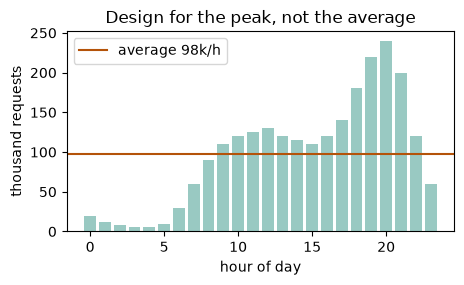

In [2]:
import matplotlib.pyplot as plt


def traffic_shape():
    hourly = [20, 12, 8, 6, 6, 10, 30, 60, 90, 110, 120, 125, 130, 120, 115, 110, 120, 140, 180, 220, 240, 200, 120, 60]
    avg = sum(hourly) / 24
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(range(24), hourly, color="#99c9c2")
    ax.axhline(avg, color="#b45309", label=f"average {avg:.0f}k/h")
    ax.set_xlabel("hour of day"); ax.set_ylabel("thousand requests"); ax.legend()
    ax.set_title("Design for the peak, not the average")


traffic_shape()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q20](#q20), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 3: From numbers to machines

*Level: Core*

- **Servers** = peak QPS ÷ (capacity per server × target utilisation), plus spares for failures and deploys.
- **Shards**: enough for both the data size *and* the throughput — whichever needs more.
- **Cache**: the 80/20 rule — about 20% of objects get 80% of reads, so cache the hot set, not everything.
- **Connections**: Little's law — concurrent = arrival rate × time each stays open. Websockets that stay open for minutes need very different servers from 50 ms HTTP requests.
- **Read/write ratio** shapes everything: read-heavy → caches and read replicas; write-heavy → partitioning, queues and log-structured storage.

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q16](#q16), [Q8](#q8), [Q9](#q9), [Q4](#q4), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 4: Latency and availability

*Level: Core*

**Latency adds up along a request's path**: count the network hops and disk reads. A cross-region call costs more than a hundred in-data-centre calls.



**Availability multiplies**: a request that needs three services at 99.9% each is only 99.7% available. Redundancy fixes it: two independent copies at 99.5% give 99.9975%. Know your nines: 99.9% allows ~8.8 hours of downtime a year; 99.99% only ~53 minutes.



**Tail latency**: when one request fans out to many services and waits for all, rare slow calls become common — with 100 calls, 63% of requests hit at least one p99-slow call. That's why large systems use timeouts, hedged requests and partial results.

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q15](#q15), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 5: IDs, units, cost and growth

*Level: Advanced*

- **IDs**: n items need ⌈log₂ n⌉ bits, or ⌈log₆₂ n⌉ base-62 characters (7 characters cover 3.5 trillion).
- **Cost** is a requirement too: tiering cold data to archive storage often cuts the bill by 70–80%.
- **Growth**: estimate when each resource runs out at the current growth rate, and say what you'd change before then.

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q18](#q18), [Q10](#q10). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Requests per Second

🟢 Warm-up · *Average and peak*

`dau` users each make `per_user` requests a day. Return `(average QPS, peak QPS)` with peak = average × `peak_factor`, both rounded to whole numbers.

**Examples**

- `dau = 10000000, per_user = 20, peak_factor = 3` → `(2315, 6944)`
- `dau = 500000, per_user = 4, peak_factor = 5` → `(23, 116)`

In [ ]:
def qps(dau, per_user, peak_factor):
    """
    dau users each make per_user requests a day. Return (average QPS, peak QPS)
    with peak = average × peak_factor, both rounded to whole numbers.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(qps, [
    ((10000000, 20, 3), (2315, 6944)),
    ((500000, 4, 5), (23, 116)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply, then divide by the seconds in a day.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, as one expression with 86,400 written once.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply, then divide by the seconds in a day.

```python
def qps(dau, per_user, peak_factor):
    per_day = dau * per_user
    avg = per_day / (24 * 60 * 60)
    return (round(avg), round(avg * peak_factor))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, as one expression with 86,400 written once.

```python
def qps(dau, per_user, peak_factor):
    avg = dau * per_user / 86_400
    return (round(avg), round(avg * peak_factor))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply, then divide by the seconds in a day. That costs O(1) time and O(1) space."

"I can do better: Same, as one expression with 86,400 written once. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/requests-per-second)

<a id="q2"></a>
### Q2. How Much Storage?

🟢 Warm-up · *Items × size × time × replicas*

Each day `items` new records of `bytes_each` bytes are stored, kept for `years` years with `replicas` copies. Return terabytes (10¹² bytes), rounded to 1.

**Examples**

- `items = 100000000, bytes_each = 500, years = 5, replicas = 3` → `273.8`
- `items = 2000000, bytes_each = 2000000, years = 1, replicas = 3` → `4380.0`

In [ ]:
def storage_tb(items, bytes_each, years, replicas):
    """
    Each day items new records of bytes_each bytes are stored, kept for years
    years with replicas copies. Return terabytes (10¹² bytes), rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(storage_tb, [
    ((100000000, 500, 5, 3), 273.8),
    ((2000000, 2000000, 1, 3), 4380.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step: per day, per year, total, replicas.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One product.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Step by step: per day, per year, total, replicas.

```python
def storage_tb(items, bytes_each, years, replicas):
    per_day = items * bytes_each
    per_year = per_day * 365
    total = per_year * years * replicas
    return round(total / 1e12, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One product.

```python
def storage_tb(items, bytes_each, years, replicas):
    return round(items * bytes_each * 365 * years * replicas / 1e12, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step: per day, per year, total, replicas. That costs O(1) time and O(1) space."

"I can do better: One product. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-much-storage)

<a id="q3"></a>
### Q3. Bandwidth In and Out

🟢 Warm-up · *MB per second*

Writes arrive at `write_qps` of `write_kb` KB each; reads at `read_qps` of `read_kb` KB each. Return `(ingress MB/s, egress MB/s)` rounded to 1 (1 MB = 1000 KB).

**Examples**

- `write_qps = 2000, write_kb = 1, read_qps = 40000, read_kb = 50` → `(2.0, 2000.0)`

In [ ]:
def bandwidth(write_qps, write_kb, read_qps, read_kb):
    """
    Writes arrive at write_qps of write_kb KB each; reads at read_qps of read_kb
    KB each. Return (ingress MB/s, egress MB/s) rounded to 1 (1 MB = 1000 KB).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bandwidth, [
    ((2000, 1, 40000, 50), (2.0, 2000.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two products and divisions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One tuple expression.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two products and divisions.

```python
def bandwidth(write_qps, write_kb, read_qps, read_kb):
    ingress = write_qps * write_kb / 1000
    egress = read_qps * read_kb / 1000
    return (round(ingress, 1), round(egress, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One tuple expression.

```python
def bandwidth(write_qps, write_kb, read_qps, read_kb):
    return tuple(round(q * kb / 1000, 1) for q, kb in ((write_qps, write_kb), (read_qps, read_kb)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two products and divisions. That costs O(1) time and O(1) space."

"I can do better: One tuple expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/bandwidth-in-and-out)

<a id="q4"></a>
### Q4. Read-Heavy or Write-Heavy?

🟢 Warm-up · *Shape the design*

Given reads and writes per second, return `(ratio reads:writes rounded to 1, label)`: 'read-heavy' if the ratio ≥ 10, 'write-heavy' if ≤ 0.5, else 'balanced'. Read-heavy systems lean on caches and replicas; write-heavy ones on partitioning and log-structured storage.

**Examples**

- `reads = 50000, writes = 500` → `(100.0, 'read-heavy')`
- `reads = 2000, writes = 8000` → `(0.2, 'write-heavy')`
- `reads = 3000, writes = 1500` → `(2.0, 'balanced')`

In [ ]:
def workload(reads, writes):
    """
    Given reads and writes per second, return (ratio reads:writes rounded to 1,
    label): 'read-heavy' if the ratio ≥ 10, 'write-heavy' if ≤ 0.5, else
    'balanced'. Read-heavy systems lean on caches and replicas; write-heavy ones
    on partitioning and log-structured storage.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(workload, [
    ((50000, 500), (100.0, 'read-heavy')),
    ((2000, 8000), (0.2, 'write-heavy')),
    ((3000, 1500), (2.0, 'balanced')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if-chain.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A conditional expression.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** An if-chain.

```python
def workload(reads, writes):
    ratio = reads / writes
    if ratio >= 10:
        label = "read-heavy"
    elif ratio <= 0.5:
        label = "write-heavy"
    else:
        label = "balanced"
    return (round(ratio, 1), label)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A conditional expression.

```python
def workload(reads, writes):
    r = reads / writes
    return (round(r, 1), "read-heavy" if r >= 10 else "write-heavy" if r <= 0.5 else "balanced")
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if-chain. That costs O(1) time and O(1) space."

"I can do better: A conditional expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/read-heavy-or-write-heavy)

<a id="q5"></a>
### Q5. Add Up a Request's Latency

🟢 Warm-up · *Latency numbers*

Using typical latencies in microseconds (`LATENCY_US`), return the total in milliseconds (rounded to 2) for a request path given as a list of steps.

**Examples**

- `steps = ['same_dc', 'cache_hit', 'same_dc', 'ssd_read']` → `2.1`
- `steps = ['cross_region', 'disk_seek', 'cross_region']` → `310.0`

In [ ]:
LATENCY_US = {"memory": 0.1, "ssd_read": 100, "disk_seek": 10_000, "same_dc": 500, "cross_region": 150_000, "cache_hit": 1_000}

def path_ms(steps):
    """
    Using typical latencies in microseconds (LATENCY_US), return the total in
    milliseconds (rounded to 2) for a request path given as a list of steps.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(path_ms, [
    ((['same_dc', 'cache_hit', 'same_dc', 'ssd_read'],), 2.1),
    ((['cross_region', 'disk_seek', 'cross_region'],), 310.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop and add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sum` with a lookup.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop and add.

```python
def path_ms(steps):
    total = 0
    for s in steps:
        total += LATENCY_US[s]
    return round(total / 1000, 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sum` with a lookup.

```python
def path_ms(steps):
    return round(sum(map(LATENCY_US.get, steps)) / 1000, 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop and add. That costs O(n) time and O(1) space."

"I can do better: `sum` with a lookup. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/add-up-a-requests-latency)

<a id="q6"></a>
### Q6. What Do the Nines Mean?

🟢 Warm-up · *Availability → downtime*

For each availability percentage, return the allowed downtime per year in minutes and per 30-day month in minutes, both rounded to 1.

**Examples**

- `levels = [99.0, 99.9, 99.99, 99.999]` → `[(5256.0, 432.0), (525.6, 43.2), (52.6, 4.3), (5.3, 0.4)]`

In [ ]:
def downtime(levels):
    """
    For each availability percentage, return the allowed downtime per year in
    minutes and per 30-day month in minutes, both rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(downtime, [
    (([99.0, 99.9, 99.99, 99.999],), [(5256.0, 432.0), (525.6, 43.2), (52.6, 4.3), (5.3, 0.4)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Minutes per year × (1 − a).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Minutes per year × (1 − a).

```python
def downtime(levels):
    out = []
    for a in levels:
        down = 1 - a / 100
        out.append((round(365 * 24 * 60 * down, 1), round(30 * 24 * 60 * down, 1)))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def downtime(levels):
    return [(round(525_600 * (1 - a / 100), 1), round(43_200 * (1 - a / 100), 1)) for a in levels]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Minutes per year × (1 − a). That costs O(n) time and O(n) space."

"I can do better: A comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/what-do-the-nines-mean)

<a id="q7"></a>
### Q7. How Many Servers?

🟢 Warm-up · *Capacity with headroom*

Each server handles `per_server` requests per second; run them at most at `util` utilisation, and add `spare` extra servers so one failure (or a deploy) doesn't overload the rest. Return the server count for `peak` QPS.

**Examples**

- `peak = 120000, per_server = 2000, util = 0.7, spare = 1` → `87`
- `peak = 500, per_server = 2000, util = 0.7, spare = 1` → `2`

In [ ]:
def servers(peak, per_server, util, spare):
    """
    Each server handles per_server requests per second; run them at most at util
    utilisation, and add spare extra servers so one failure (or a deploy)
    doesn't overload the rest. Return the server count for peak QPS.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(servers, [
    ((120000, 2000, 0.7, 1), 87),
    ((500, 2000, 0.7, 1), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Increase n until n × capacity ≥ peak.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Ceiling division.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Increase n until n × capacity ≥ peak.

```python
def servers(peak, per_server, util, spare):
    n = 0
    while n * per_server * util < peak:
        n += 1
    return n + spare
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Ceiling division.

```python
def servers(peak, per_server, util, spare):
    return math.ceil(round(peak / (per_server * util), 9)) + spare
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Increase n until n × capacity ≥ peak. That costs O(n) time and O(1) space."

"I can do better: Ceiling division. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-many-servers)

<a id="q8"></a>
### Q8. How Big a Cache?

🟢 Warm-up · *The 80/20 rule*

Cache the hottest `hot_share` of the objects read each day: `daily_reads` reads of `kb` KB, where each distinct object is read `reads_per_object` times a day on average. Return GB needed (1 GB = 10⁶ KB), rounded to 1.

**Examples**

- `daily_reads = 1000000000, kb = 10, reads_per_object = 20, hot_share = 0.2` → `100.0`

In [ ]:
def cache_gb(daily_reads, kb, reads_per_object, hot_share):
    """
    Cache the hottest hot_share of the objects read each day: daily_reads reads
    of kb KB, where each distinct object is read reads_per_object times a day on
    average. Return GB needed (1 GB = 10⁶ KB), rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cache_gb, [
    ((1000000000, 10, 20, 0.2), 100.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Distinct objects, then the hot share, then size.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One expression.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Distinct objects, then the hot share, then size.

```python
def cache_gb(daily_reads, kb, reads_per_object, hot_share):
    distinct = daily_reads / reads_per_object
    hot = distinct * hot_share
    return round(hot * kb / 1e6, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One expression.

```python
def cache_gb(daily_reads, kb, reads_per_object, hot_share):
    return round(daily_reads / reads_per_object * hot_share * kb / 1e6, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Distinct objects, then the hot share, then size. That costs O(1) time and O(1) space."

"I can do better: One expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-big-a-cache)

<a id="q9"></a>
### Q9. Open Connections (Little's Law)

🟢 Warm-up · *Concurrency*

Requests arrive at `rps` per second and stay open for `secs` seconds on average (long-polling and websockets stay open much longer). Return the number of concurrent connections.

**Examples**

- `rps = 50000, secs = 0.2` → `10000`
- `rps = 2000, secs = 300` → `600000`

In [ ]:
def concurrent(rps, secs):
    """
    Requests arrive at rps per second and stay open for secs seconds on average
    (long-polling and websockets stay open much longer). Return the number of
    concurrent connections.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(concurrent, [
    ((50000, 0.2), 10000),
    ((2000, 300), 600000),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply.

```python
def concurrent(rps, secs):
    return round(rps * secs)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply. That costs O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/open-connections-littles-law)

<a id="q10"></a>
### Q10. Human-Readable Sizes

🟢 Warm-up · *Units*

Format a number of bytes as the largest unit (B, KB, MB, GB, TB, PB, base 1000) that keeps the value ≥ 1, with one decimal place, e.g. '1.5 GB'.

**Examples**

- `nbytes = 999` → `'999.0 B'`
- `nbytes = 1500000000` → `'1.5 GB'`
- `nbytes = 2300000000000000.0` → `'2.3 PB'`

In [ ]:
def human(nbytes):
    """
    Format a number of bytes as the largest unit (B, KB, MB, GB, TB, PB, base
    1000) that keeps the value ≥ 1, with one decimal place, e.g. '1.5 GB'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(human, [
    ((999,), '999.0 B'),
    ((1500000000,), '1.5 GB'),
    ((2300000000000000.0,), '2.3 PB'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide by 1000 in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`log10` picks the unit directly.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Divide by 1000 in a loop.

```python
def human(nbytes):
    units = ["B", "KB", "MB", "GB", "TB", "PB"]
    i = 0
    value = nbytes
    while value >= 1000 and i < len(units) - 1:
        value /= 1000
        i += 1
    return f"{value:.1f} {units[i]}"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `log10` picks the unit directly.

```python
def human(nbytes):
    units = ["B", "KB", "MB", "GB", "TB", "PB"]
    i = min(len(units) - 1, int(math.log10(nbytes) // 3)) if nbytes >= 1 else 0
    return f"{nbytes / 1000 ** i:.1f} {units[i]}"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide by 1000 in a loop. That costs O(1) time and O(1) space."

"I can do better: `log10` picks the unit directly. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/human-readable-sizes)

<a id="q11"></a>
### Q11. How Long Must an ID Be?

🟢 Warm-up · *Bits and characters*

To give `n` things unique IDs, return `(bits needed, base-62 characters needed)`.

**Examples**

- `n = 1000000` → `(20, 4)`
- `n = 3500000000000` → `(42, 7)`

In [ ]:
def id_length(n):
    """
    To give n things unique IDs, return (bits needed, base-62 characters
    needed).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(id_length, [
    ((1000000,), (20, 4)),
    ((3500000000000,), (42, 7)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Double / multiply until the capacity reaches n.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Logarithms with a ceiling.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Double / multiply until the capacity reaches n.

```python
def id_length(n):
    bits, cap = 0, 1
    while cap < n:
        cap *= 2
        bits += 1
    chars, cap = 0, 1
    while cap < n:
        cap *= 62
        chars += 1
    return (bits, chars)
```

**Cost:** O(log n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Logarithms with a ceiling.

```python
def id_length(n):
    return (math.ceil(math.log2(n)), math.ceil(round(math.log(n, 62), 12)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Double / multiply until the capacity reaches n. That costs O(log n) time and O(1) space."

"I can do better: Logarithms with a ceiling. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-long-must-an-id-be)

<a id="q12"></a>
### Q12. What Will Storage Cost?

🟢 Warm-up · *Money matters in design*

Store `tb` TB on standard storage at `std` \$/GB-month, or keep the newest `hot_share` on standard and move the rest to archive storage at `archive` \$/GB-month. Return `(monthly $ all-standard, monthly $ tiered)` rounded to 0.

**Examples**

- `tb = 500, std = 0.023, archive = 0.004, hot = 0.1` → `(11500, 2950)`

In [ ]:
def storage_cost(tb, std, archive, hot):
    """
    Store tb TB on standard storage at std $/GB-month, or keep the newest
    hot_share on standard and move the rest to archive storage at archive $/GB-
    month. Return (monthly $ all-standard, monthly $ tiered) rounded to 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(storage_cost, [
    ((500, 0.023, 0.004, 0.1), (11500, 2950)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two products.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with GB computed once.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two products.

```python
def storage_cost(tb, std, archive, hot_share):
    gb = tb * 1000
    all_std = gb * std
    tiered = gb * hot_share * std + gb * (1 - hot_share) * archive
    return (round(all_std), round(tiered))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with GB computed once.

```python
def storage_cost(tb, std, archive, hot):
    gb = tb * 1000
    return (round(gb * std), round(gb * (hot * std + (1 - hot) * archive)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two products. That costs O(1) time and O(1) space."

"I can do better: Same, with GB computed once. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/what-will-storage-cost)

<a id="q13"></a>
### Q13. How Big Is One Record?

🟢 Warm-up · *Size from the schema*

Add up a record's size: fixed types from `SIZES`, and `(varchar, n)` fields at n bytes (worst case). Return bytes, and the size of a million records in MB (rounded to 1).

**Examples**

- `schema = {'user_id': 'bigint', 'created_at': 'timestamp', 'text': ('varchar', 140), 'lat': 'double', 'lon': 'double', 'flags': 'int', 'media_url': ('varchar', 200)}` → `(376, 376)`

In [ ]:
SIZES = {"bigint": 8, "int": 4, "double": 8, "timestamp": 8, "bool": 1}

def record_size(schema):
    """
    Add up a record's size: fixed types from SIZES, and (varchar, n) fields at n
    bytes (worst case). Return bytes, and the size of a million records in MB
    (rounded to 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(record_size, [
    (({'user_id': 'bigint', 'created_at': 'timestamp', 'text': ('varchar', 140), 'lat': 'double', 'lon': 'double', 'flags': 'int', 'media_url': ('varchar', 200)},), (376, 376)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with an isinstance check.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sum` over a conditional expression.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with an isinstance check.

```python
def record_size(schema):
    total = 0
    for t in schema.values():
        if isinstance(t, tuple):
            total += t[1]
        else:
            total += SIZES[t]
    return (total, round(total * 1_000_000 / 1e6, 1))
```

**Cost:** O(f) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sum` over a conditional expression.

```python
def record_size(schema):
    total = sum(t[1] if isinstance(t, tuple) else SIZES[t] for t in schema.values())
    return (total, round(total, 1))
```

**Cost:** O(f) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with an isinstance check. That costs O(f) time and O(1) space."

"I can do better: `sum` over a conditional expression. That's O(f) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-big-is-one-record)

<a id="q14"></a>
### Q14. Functional or Non-Functional?

🟢 Warm-up · *Requirements first*

Sort requirement statements: non-functional if they mention any keyword in `NFR` (case-insensitive), otherwise functional. Return `(functional, non_functional)` lists in order. Clarifying both kinds is the first five minutes of every design interview.

**Examples**

- `statements = ['Users can shorten a long URL', 'Redirects complete within 100 ms', 'Links never expire unless deleted', 'The service is available 99.99% of the time', 'Users can see click counts']` → `(['Users can shorten a long URL', 'Links never expire unless deleted', 'Users can see click counts'], ['Redirects complete within 100 ms', 'The service is available 99.99% of the time'])`

In [ ]:
NFR = ["latency", "available", "availability", "scale", "durable", "consistent", "secure", "throughput", "cost", "within", "ms", "99."]

def split_requirements(statements):
    """
    Sort requirement statements: non-functional if they mention any keyword in
    NFR (case-insensitive), otherwise functional. Return (functional,
    non_functional) lists in order. Clarifying both kinds is the first five
    minutes of every design interview.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split_requirements, [
    ((['Users can shorten a long URL', 'Redirects complete within 100 ms', 'Links never expire unless deleted', 'The service is available 99.99% of the time', 'Users can see click counts'],), (['Users can shorten a long URL', 'Links never expire unless deleted', 'Users can see click counts'], ['Redirects complete within 100 ms', 'The service is available 99.99% of the time'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop over statements and keywords.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`any` inside two comprehensions.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop over statements and keywords.

```python
def split_requirements(statements):
    func, nonfunc = [], []
    for s in statements:
        found = False
        for k in NFR:
            if k in s.lower():
                found = True
                break
        (nonfunc if found else func).append(s)
    return (func, nonfunc)
```

**Cost:** O(s · k) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `any` inside two comprehensions.

```python
def split_requirements(statements):
    nf = lambda s: any(k in s.lower() for k in NFR)
    return ([s for s in statements if not nf(s)], [s for s in statements if nf(s)])
```

**Cost:** O(s · k) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop over statements and keywords. That costs O(s · k) time and O(s) space."

"I can do better: `any` inside two comprehensions. That's O(s · k) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/functional-or-non-functional)

<a id="q15"></a>
### Q15. Availability in Series and in Parallel

🟡 Interview standard · *Dependencies vs redundancy*

A request needs every component in `chain` (availability fractions). One of them, at index `k`, can be made redundant with `copies` independent copies. Return `(availability before, after)` as percentages rounded to 3.

**Examples**

- `chain = [0.999, 0.995, 0.9999], k = 1, copies = 2` → `(99.391, 99.888)`
- `chain = [0.99, 0.99, 0.99], k = 0, copies = 3` → `(97.03, 98.01)`

In [ ]:
def availability(chain, k, copies):
    """
    A request needs every component in chain (availability fractions). One of
    them, at index k, can be made redundant with copies independent copies.
    Return (availability before, after) as percentages rounded to 3.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(availability, [
    (([0.999, 0.995, 0.9999], 1, 2), (99.391, 99.888)),
    (([0.99, 0.99, 0.99], 0, 3), (97.03, 98.01)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply in a loop; the redundant part is 1 − (1 − a)ⁿ.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.prod`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply in a loop; the redundant part is 1 − (1 − a)ⁿ.

```python
def availability(chain, k, copies):
    before = 1.0
    for a in chain:
        before *= a
    after = 1.0
    for i, a in enumerate(chain):
        after *= (1 - (1 - a) ** copies) if i == k else a
    return (round(before * 100, 3), round(after * 100, 3))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `math.prod`.

```python
def availability(chain, k, copies):
    improved = [1 - (1 - a) ** copies if i == k else a for i, a in enumerate(chain)]
    return (round(math.prod(chain) * 100, 3), round(math.prod(improved) * 100, 3))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply in a loop; the redundant part is 1 − (1 − a)ⁿ. That costs O(n) time and O(n) space."

"I can do better: `math.prod`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/availability-in-series-and-in-parallel)

<a id="q16"></a>
### Q16. How Many Shards?

🟡 Interview standard · *Size and throughput both count*

Each shard holds at most `shard_tb` TB and serves `shard_qps` QPS. Return `(shards for data, shards for traffic, shards needed)` for `data_tb` TB at `qps`.

**Examples**

- `data_tb = 120, shard_tb = 2, qps_ = 300000, shard_qps = 25000` → `(60, 12, 60)`
- `data_tb = 10, shard_tb = 2, qps_ = 300000, shard_qps = 25000` → `(5, 12, 12)`

In [ ]:
def shards(data_tb, shard_tb, qps_, shard_qps):
    """
    Each shard holds at most shard_tb TB and serves shard_qps QPS. Return
    (shards for data, shards for traffic, shards needed) for data_tb TB at qps.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shards, [
    ((120, 2, 300000, 25000), (60, 12, 60)),
    ((10, 2, 300000, 25000), (5, 12, 12)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two ceiling divisions and a max.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with `math.ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two ceiling divisions and a max.

```python
def shards(data_tb, shard_tb, qps_, shard_qps):
    by_data = data_tb // shard_tb + (1 if data_tb % shard_tb else 0)
    by_qps = qps_ // shard_qps + (1 if qps_ % shard_qps else 0)
    return (by_data, by_qps, max(by_data, by_qps))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same with `math.ceil`.

```python
def shards(data_tb, shard_tb, qps_, shard_qps):
    d, q = math.ceil(data_tb / shard_tb), math.ceil(qps_ / shard_qps)
    return (d, q, max(d, q))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two ceiling divisions and a max. That costs O(1) time and O(1) space."

"I can do better: Same with `math.ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/how-many-shards)

<a id="q17"></a>
### Q17. Fan-Out Makes the Tail Worse

🟡 Interview standard · *Tail latency*

A request calls `n` back-end services in parallel and waits for all. If each is fast 99% of the time (p99), what % of requests hit at least one slow call? Return values for each n, rounded to 1.

**Examples**

- `ns = [1, 10, 50, 100]` → `[1.0, 9.6, 39.5, 63.4]`

In [ ]:
def slow_share(ns):
    """
    A request calls n back-end services in parallel and waits for all. If each
    is fast 99% of the time (p99), what % of requests hit at least one slow
    call? Return values for each n, rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(slow_share, [
    (([1, 10, 50, 100],), [1.0, 9.6, 39.5, 63.4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

1 − 0.99ⁿ in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** 1 − 0.99ⁿ in a loop.

```python
def slow_share(ns):
    out = []
    for n in ns:
        out.append(round((1 - 0.99 ** n) * 100, 1))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def slow_share(ns):
    return [round((1 - 0.99 ** n) * 100, 1) for n in ns]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: 1 − 0.99ⁿ in a loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/fan-out-makes-the-tail-worse)

<a id="q18"></a>
### Q18. When Will We Run Out?

🟡 Interview standard · *Growth planning*

Storage is `used` TB of `capacity` TB and grows `pct`% a month (compounding). Return the number of whole months until it's full (the first month the usage exceeds capacity).

**Examples**

- `used = 40, capacity = 100, pct = 8` → `12`
- `used = 90, capacity = 100, pct = 1` → `11`

In [ ]:
def months_left(used, capacity, pct):
    """
    Storage is used TB of capacity TB and grows pct% a month (compounding).
    Return the number of whole months until it's full (the first month the usage
    exceeds capacity).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(months_left, [
    ((40, 100, 8), 12),
    ((90, 100, 1), 11),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply month by month.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Solve with logarithms, then ceiling.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply month by month.

```python
def months_left(used, capacity, pct):
    months = 0
    while used <= capacity:
        used *= 1 + pct / 100
        months += 1
    return months
```

**Cost:** O(months) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Solve with logarithms, then ceiling.

```python
def months_left(used, capacity, pct):
    m = math.log(capacity / used) / math.log(1 + pct / 100)
    return math.floor(m) + 1
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply month by month. That costs O(months) time and O(1) space."

"I can do better: Solve with logarithms, then ceiling. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/when-will-we-run-out)

<a id="q19"></a>
### Q19. Estimate a Whole System

🟡 Interview standard · *Putting it together*

For a photo app: `dau` users, each uploads `uploads` photos a day of `mb` MB and views `views` photos a day. Return a dict: upload QPS (avg, rounded), view QPS (avg, rounded), new storage per day in TB (rounded to 1), and egress in GB/s at average load (rounded to 1).

**Examples**

- `dau = 50000000, up = 0.2, mb = 2, views = 60` → `{'upload_qps': 116, 'view_qps': 34722, 'storage_tb_per_day': 20.0, 'egress_gb_s': 69.4}`

In [ ]:
def photo_app(dau, up, mb, views):
    """
    For a photo app: dau users, each uploads uploads photos a day of mb MB and
    views views photos a day. Return a dict: upload QPS (avg, rounded), view QPS
    (avg, rounded), new storage per day in TB (rounded to 1), and egress in GB/s
    at average load (rounded to 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(photo_app, [
    ((50000000, 0.2, 2, 60), {'upload_qps': 116, 'view_qps': 34722, 'storage_tb_per_day': 20.0, 'egress_gb_s': 69.4}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each figure step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dict built from shared intermediate values.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute each figure step by step.

```python
def photo_app(dau, uploads, mb, views):
    upload_qps = dau * uploads / 86400
    view_qps = dau * views / 86400
    storage_tb = dau * uploads * mb / 1e6
    egress = view_qps * mb / 1000
    return {"upload_qps": round(upload_qps), "view_qps": round(view_qps),
            "storage_tb_per_day": round(storage_tb, 1), "egress_gb_s": round(egress, 1)}
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dict built from shared intermediate values.

```python
def photo_app(dau, up, mb, views):
    vq = dau * views / 86_400
    return {"upload_qps": round(dau * up / 86_400), "view_qps": round(vq),
            "storage_tb_per_day": round(dau * up * mb / 1e6, 1), "egress_gb_s": round(vq * mb / 1000, 1)}
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each figure step by step. That costs O(1) time and O(1) space."

"I can do better: A dict built from shared intermediate values. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/estimate-a-whole-system)

<a id="q20"></a>
### Q20. Find the Real Peak From Traffic

🟡 Interview standard · *Use data, not guesses*

`hourly` holds thousands of requests in each hour of a day. Return `(average QPS, peak-hour QPS, peak ÷ average rounded to 2)`, QPS rounded to whole numbers. Design for the peak (and the busiest minute inside it is higher still).

**Examples**

- `hourly = [20, 12, 8, 6, 6, 10, 30, 60, 90, 110, 120, 125, 130, 120, 115, 110, 120, 140, 180, 220, 240, 200, 120, 60]` → `(27, 67, 2.45)`

In [ ]:
def real_peak(hourly):
    """
    hourly holds thousands of requests in each hour of a day. Return (average
    QPS, peak-hour QPS, peak ÷ average rounded to 2), QPS rounded to whole
    numbers. Design for the peak (and the busiest minute inside it is higher
    still).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(real_peak, [
    (([20, 12, 8, 6, 6, 10, 30, 60, 90, 110, 120, 125, 130, 120, 115, 110, 120, 140, 180, 220, 240, 200, 120, 60],), (27, 67, 2.45)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum and max in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sum` and `max`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sum and max in a loop.

```python
def real_peak(hourly):
    total, peak = 0, 0
    for h in hourly:
        total += h
        if h > peak:
            peak = h
    avg_qps = total * 1000 / 86400
    peak_qps = peak * 1000 / 3600
    return (round(avg_qps), round(peak_qps), round(peak_qps / avg_qps, 2))
```

**Cost:** O(24) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sum` and `max`.

```python
def real_peak(hourly):
    avg, peak = sum(hourly) * 1000 / 86_400, max(hourly) * 1000 / 3600
    return (round(avg), round(peak), round(peak / avg, 2))
```

**Cost:** O(24) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum and max in a loop. That costs O(24) time and O(1) space."

"I can do better: `sum` and `max`. That's O(24) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/estimation/find-the-real-peak-from-traffic)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why estimate at all?</b></summary>

The numbers decide the design: 100 QPS fits on one server with one database; 1 million QPS needs caching, sharding and many replicas. Estimating shows the interviewer you design for the real scale.

</details>

<details>
<summary><b>2. How do you handle a peak you can't predict?</b></summary>

Design for the expected peak with headroom, autoscale stateless tiers, queue or shed load gracefully, and rate-limit per client so one burst can't take everything down.

</details>

<details>
<summary><b>3. Why does availability drop as you add dependencies?</b></summary>

A request succeeds only if every service it needs succeeds, so availabilities multiply. Redundancy, timeouts, fallbacks and removing hard dependencies push it back up.

</details>

<details>
<summary><b>4. What is tail latency and why does it matter?</b></summary>

The slowest requests (p99, p999). With fan-out to many services, a rare slow call becomes likely for each user request, so the tail of each service sets the typical latency of the whole system.

</details>

<details>
<summary><b>5. How precise should estimates be?</b></summary>

Within an order of magnitude. Round to easy numbers, state assumptions, and focus on what the numbers imply for the design.

</details>

<details>
<summary><b>6. What's the first thing you do in a design interview?</b></summary>

Clarify requirements — functional and non-functional — and agree the scope with the interviewer before drawing anything.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: How a system design interview works
- [ ] I can explain: Estimation: the numbers to know
- [ ] I can explain: From numbers to machines
- [ ] I can explain: Latency and availability
- [ ] I can explain: IDs, units, cost and growth

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) How Many Shards?
- [ ] [Q17](#q17) Fan-Out Makes the Tail Worse
- [ ] [Q18](#q18) When Will We Run Out?
- [ ] [Q19](#q19) Estimate a Whole System
- [ ] [Q20](#q20) Find the Real Peak From Traffic

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.